# A549 EMT figure reproduction

Choose `ds = "TGFB1"`, `"TNF"`, or `"EGF"` in the first code cell. The notebook reads the matching precomputed per-cell table from `source_data/` and reproduces the figures without loading AnnData or running the analysis pipeline.

Inputs: `source_data/Input_A549_TGFB1_percell.csv`, `source_data/Input_A549_TNF_percell.csv`, and `source_data/Input_A549_EGF_percell.csv`.

Figures are written to `figures/`; derived summaries and statistics are written to `source_data/`. Dataset: A549 cells from GSE147405 (Cook and Vanderhyden, 2020).

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr, spearmanr, ttest_ind
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

# Choose one dataset: TGFB1, TNF, or EGF.
ds = "TNF"
if ds not in {"TGFB1", "TNF", "EGF"}:
    raise ValueError("ds must be one of: TGFB1, TNF, EGF")

FIGURES = Path('figures')
SOURCE = Path('source_data')
FIGURES.mkdir(exist_ok=True)
SOURCE.mkdir(exist_ok=True)

mpl.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 600, 'savefig.bbox': 'tight',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'axes.linewidth': 0.9, 'axes.labelsize': 12, 'axes.titlesize': 13,
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
})
sns.set_theme(style='white', context='paper', rc=mpl.rcParams)

TIME_ORDER = ['0d', '8h', '1d', '3d', '7d', '8h_rm', '1d_rm', '3d_rm']
TIME_COLORS = dict(zip(TIME_ORDER, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'gold', 'tab:brown', 'tab:pink']))

cells = pd.read_csv(SOURCE / f'Input_A549_{ds}_percell.csv', index_col='cell_id')
cells['Time'] = pd.Categorical(cells['Time'], categories=TIME_ORDER, ordered=True)
print(f'{len(cells):,} cells | {cells["Time"].nunique()} time points | dataset: {ds}')
print(cells.isna().sum().to_string())

def save_figure(fig, name):
    fig.savefig(FIGURES / f'{ds}_{name}.png')
    fig.savefig(FIGURES / f'{ds}_{name}.pdf')

def title(ax, text):
    ax.set_title(f'A549 {ds} - {text}')

12,911 cells | 8 time points | dataset: TNF
Time          0
phenotype     0
CCAT          0
KS_score      0
GS76_score    0
ID            0
KS_epi        0
KS_mes        0
Pseudotime    0


## CCAT across time and phenotype

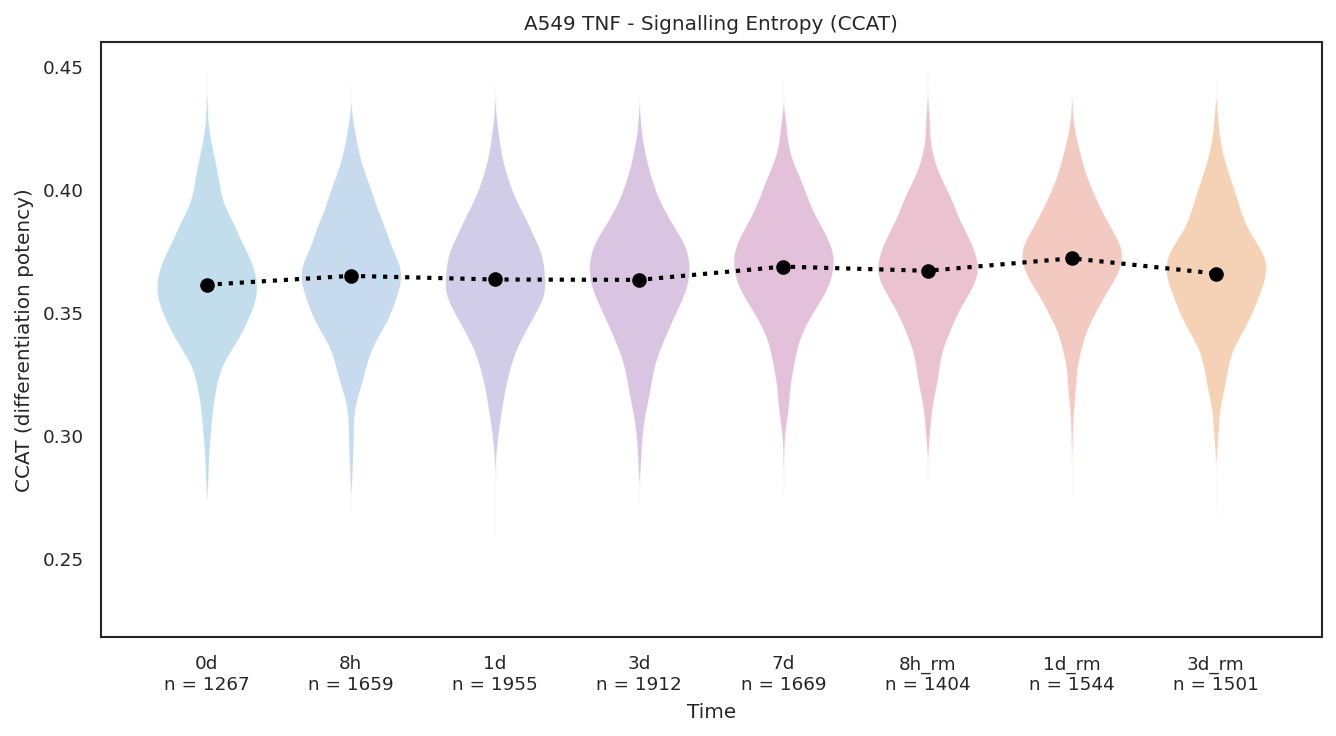

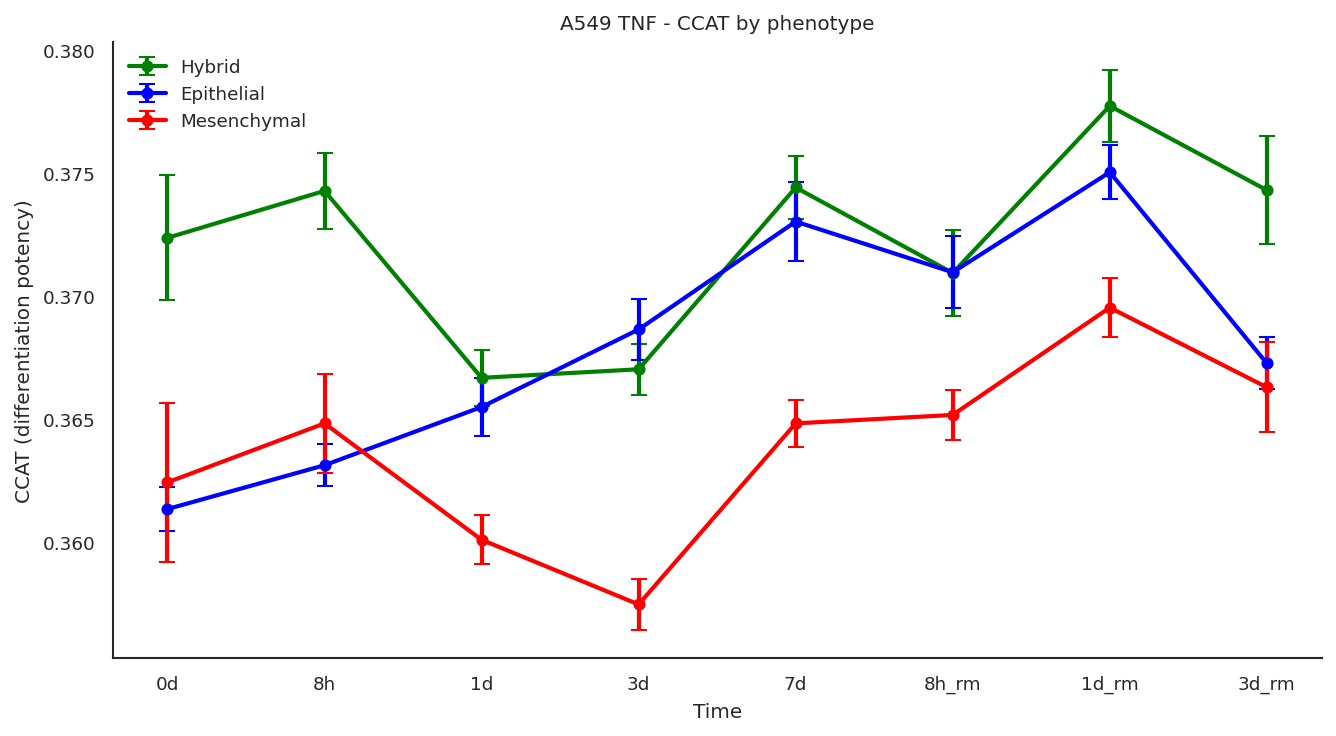

In [2]:
pastel_colors = [
    '#B8D8E8', '#BFD4EA', '#C9C4E4', '#D3BBDD',
    '#DEB6D5', '#E8B8C8', '#F0C1B8', '#F4C9A8'
]

ccat_groups = [
    cells.loc[cells['Time'] == time, 'CCAT'].dropna().to_numpy()
    for time in TIME_ORDER
]
ccat_means = [values.mean() for values in ccat_groups]
cell_counts = cells['Time'].value_counts().reindex(TIME_ORDER)
positions = np.arange(len(TIME_ORDER))

fig, ax = plt.subplots(figsize=(9, 5))
parts = ax.violinplot(
    ccat_groups,
    positions=positions,
    widths=0.7,
    showmeans=False,
    showmedians=False,
    showextrema=False
)
for body, color in zip(parts['bodies'], pastel_colors):
    body.set_facecolor(color)
    body.set_alpha(0.85)

ax.plot(
    positions,
    ccat_means,
    linestyle=':',
    marker='o',
    linewidth=2,
    markersize=6,
    color='black'
)
ax.set_xticks(positions)
ax.set_xticklabels([f'{time}\nn = {int(cell_counts.loc[time])}' for time in TIME_ORDER])
ax.set_xlabel('Time')
ax.set_ylabel('CCAT (differentiation potency)')
title(ax, 'Signalling Entropy (CCAT)')
fig.tight_layout()
save_figure(fig, 'panel01_ccat_across_time')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for phenotype, color in {'hybrid': 'green', 'epithelial': 'blue', 'mesenchymal': 'red'}.items():
    subset = cells[cells['phenotype'] == phenotype]
    means = subset.groupby('Time', observed=False)['CCAT'].mean().reindex(TIME_ORDER)
    sem = subset.groupby('Time', observed=False)['CCAT'].sem().reindex(TIME_ORDER)
    ax.errorbar(
        range(len(TIME_ORDER)), means, yerr=sem,
        marker='o', linewidth=2, capsize=4,
        color=color, label=phenotype.capitalize()
    )
ax.set_xticks(range(len(TIME_ORDER)))
ax.set_xticklabels(TIME_ORDER)
ax.set_xlabel('Time')
ax.set_ylabel('CCAT (differentiation potency)')
title(ax, 'CCAT by phenotype')
ax.legend(frameon=False)
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, 'panel02_ccat_by_phenotype')
plt.show()

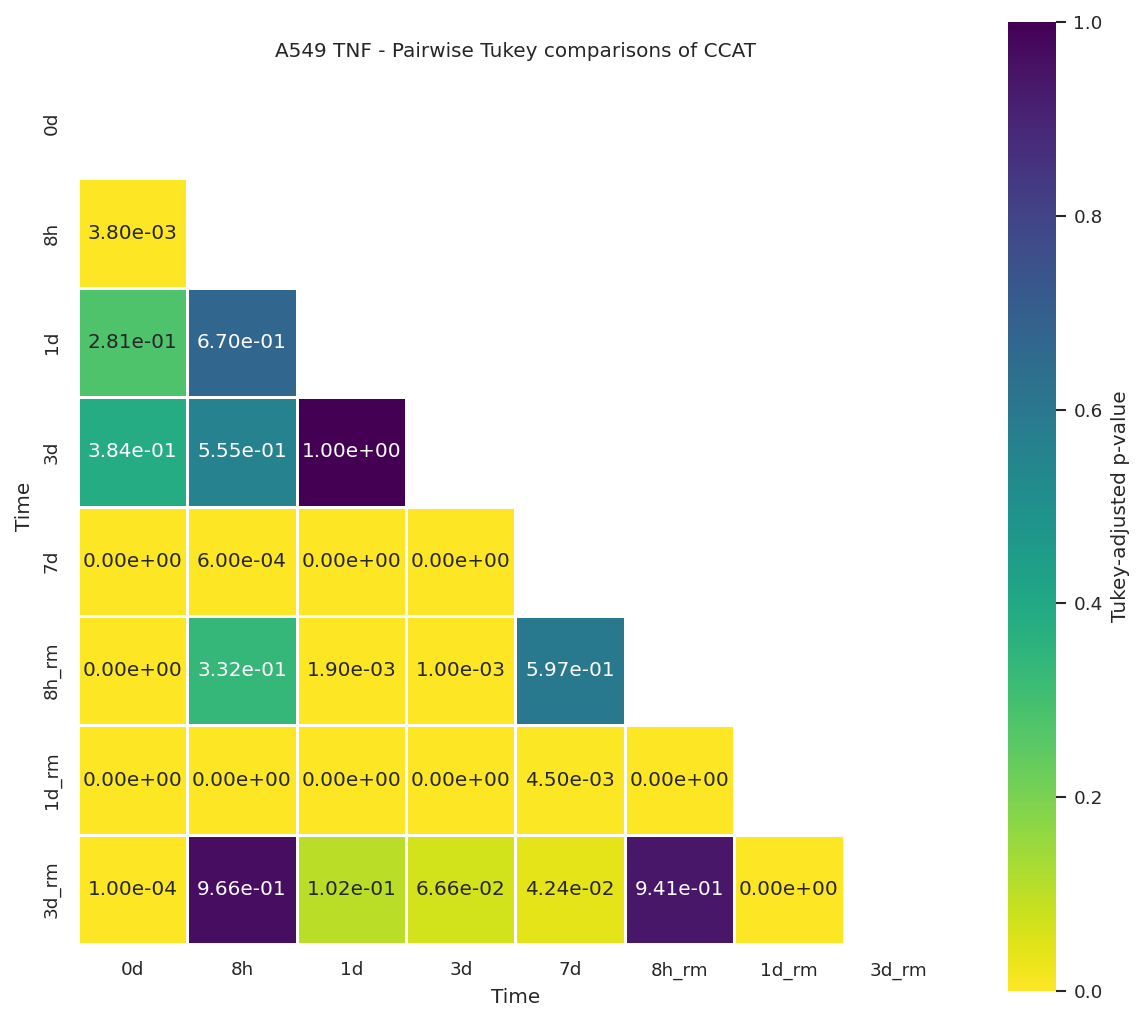

In [3]:
tukey = pairwise_tukeyhsd(cells['CCAT'], cells['Time'], alpha=0.05)
tukey_table = pd.DataFrame(tukey._results_table.data[1:], columns=tukey._results_table.data[0])
tukey_table.to_csv(SOURCE / f'{ds}_panel03_ccat_tukey.csv', index=False)
ccat_padj = pd.DataFrame(np.nan, index=TIME_ORDER, columns=TIME_ORDER)
for _, row in tukey_table.iterrows():
    ccat_padj.loc[row['group1'], row['group2']] = float(row['p-adj'])
    ccat_padj.loc[row['group2'], row['group1']] = float(row['p-adj'])
ccat_padj.to_csv(SOURCE / f'{ds}_panel03_ccat_tukey_matrix.csv')
mask = np.triu(np.ones_like(ccat_padj, dtype=bool))
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(ccat_padj, mask=mask, annot=True, fmt='.2e', cmap='viridis_r', linewidths=0.5, square=True, cbar_kws={'label': 'Tukey-adjusted p-value'}, ax=ax)
title(ax, 'Pairwise Tukey comparisons of CCAT')
ax.set_xlabel('Time'); ax.set_ylabel('Time')
fig.tight_layout()
save_figure(fig, 'panel03_ccat_tukey')
plt.show()

## EMT scores and score concordance

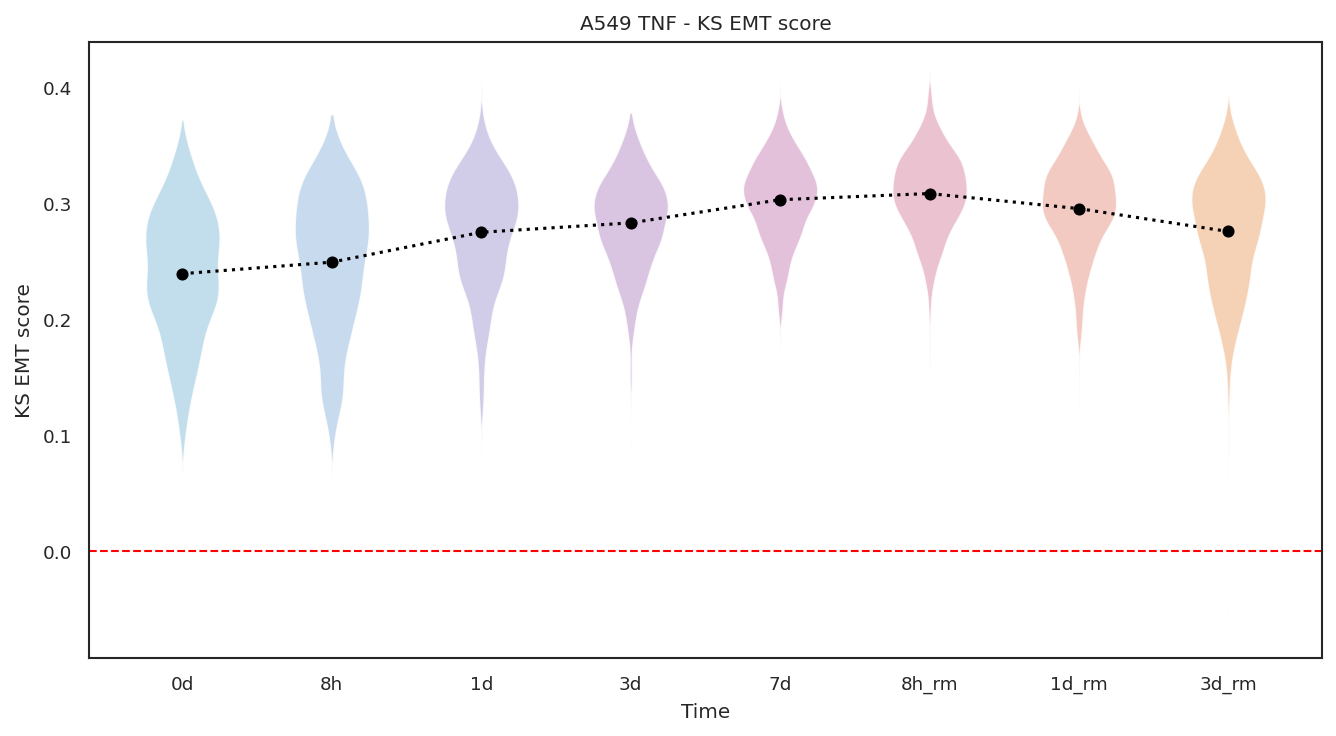

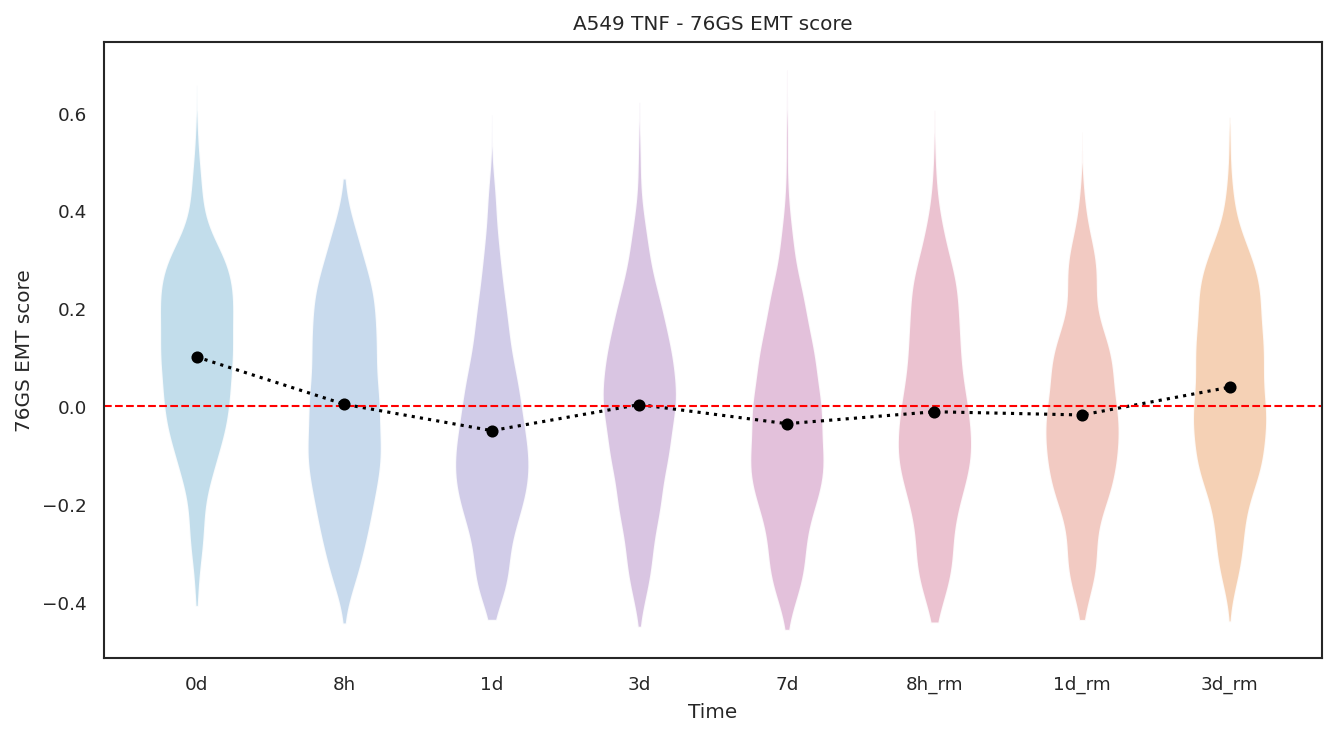

In [4]:
pastel_colors = [
    '#B8D8E8', '#BFD4EA', '#C9C4E4', '#D3BBDD',
    '#DEB6D5', '#E8B8C8', '#F0C1B8', '#F4C9A8'
]

for score, label, name in [('KS_score', 'KS EMT score', 'panel04_ks_trajectory'), ('GS76_score', '76GS EMT score', 'panel05_gs76_trajectory')]:
    data = [
        cells.loc[cells['Time'] == time, score].dropna().to_numpy()
        for time in TIME_ORDER
    ]
    positions = np.arange(len(TIME_ORDER))
    means = [values.mean() for values in data]

    fig, ax = plt.subplots(figsize=(9, 5))
    parts = ax.violinplot(
        data,
        positions=positions,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )
    for body, color in zip(parts['bodies'], pastel_colors):
        body.set_facecolor(color)
        body.set_alpha(0.85)

    ax.scatter(positions, means, color='black', s=25, zorder=3)
    ax.plot(positions, means, linestyle=':', linewidth=1.5, color='black', zorder=2)
    ax.axhline(0, linestyle='--', linewidth=1, color='red')
    ax.set_xticks(positions)
    ax.set_xticklabels(TIME_ORDER)
    ax.set_xlabel('Time')
    ax.set_ylabel(label)
    title(ax, label)
    fig.tight_layout()
    save_figure(fig, name)
    plt.show()

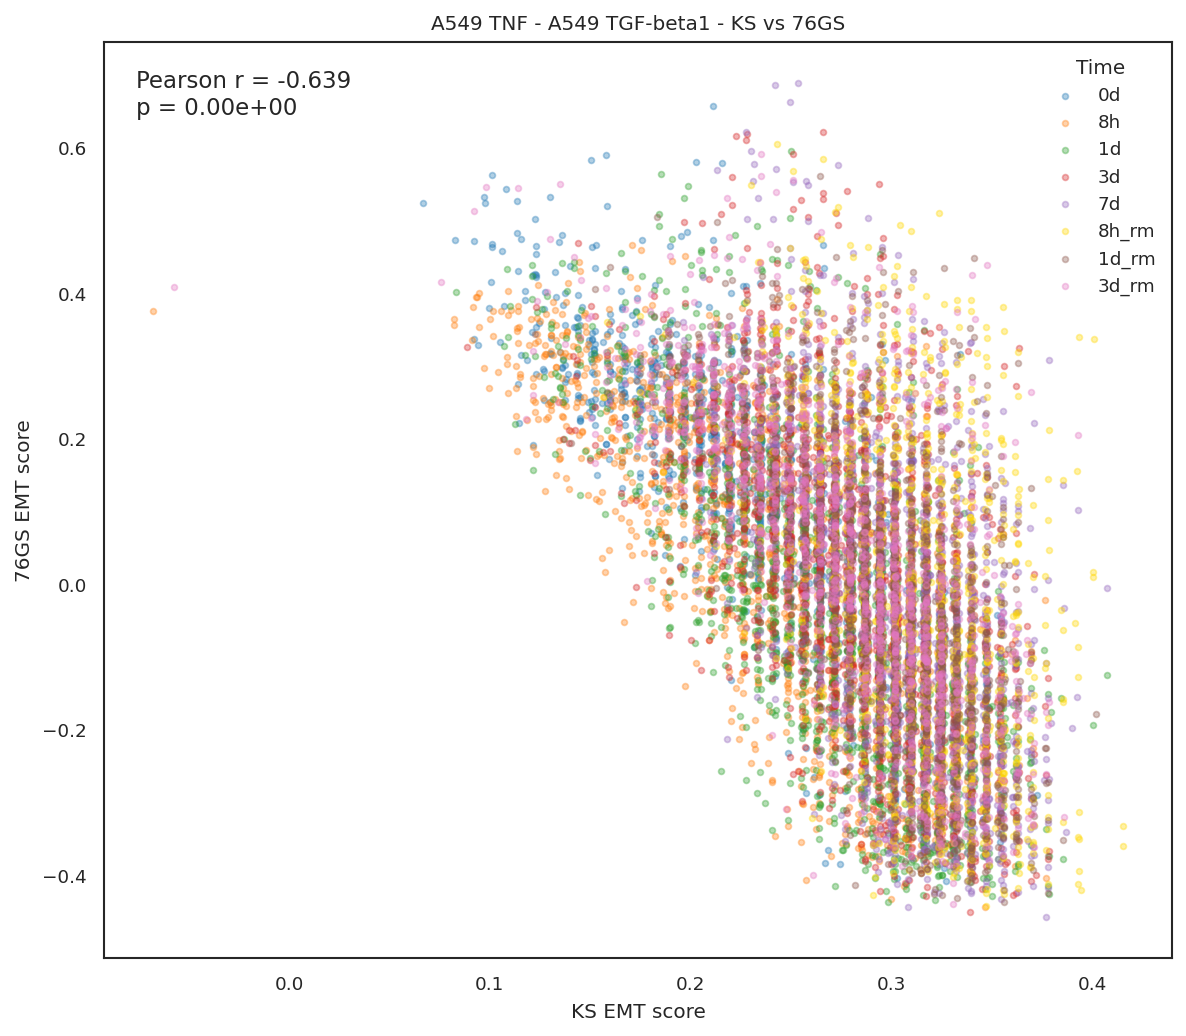

In [5]:
def correlation_table(x, y, name):
    data = cells[[x, y]].dropna()
    pearson = pearsonr(data[x], data[y])
    spearman = spearmanr(data[x], data[y])
    pd.DataFrame([{'method': 'pearson', 'r': pearson.statistic, 'p': pearson.pvalue}, {'method': 'spearman', 'r': spearman.statistic, 'p': spearman.pvalue}]).to_csv(SOURCE / name, index=False)
    return data, pearson

data, pearson = correlation_table('KS_score', 'GS76_score', 'panel06_ks_vs_gs76_correlation.csv')
fig, ax = plt.subplots(figsize=(8, 7))
for time in TIME_ORDER:
    subset = cells[cells['Time'] == time]
    ax.scatter(subset['KS_score'], subset['GS76_score'], s=8, alpha=0.35, color=TIME_COLORS[time], label=time)
ax.text(0.03, 0.97, f'Pearson r = {pearson.statistic:.3f}\np = {pearson.pvalue:.2e}', transform=ax.transAxes, ha='left', va='top', fontsize=11)
ax.set_xlabel('KS EMT score'); ax.set_ylabel('76GS EMT score')
title(ax, 'A549 TGF-beta1 - KS vs 76GS')
ax.legend(title='Time', frameon=False)
fig.tight_layout(); save_figure(fig, 'panel06_ks_vs_gs76'); plt.show()

## Pairwise EMT-score comparisons

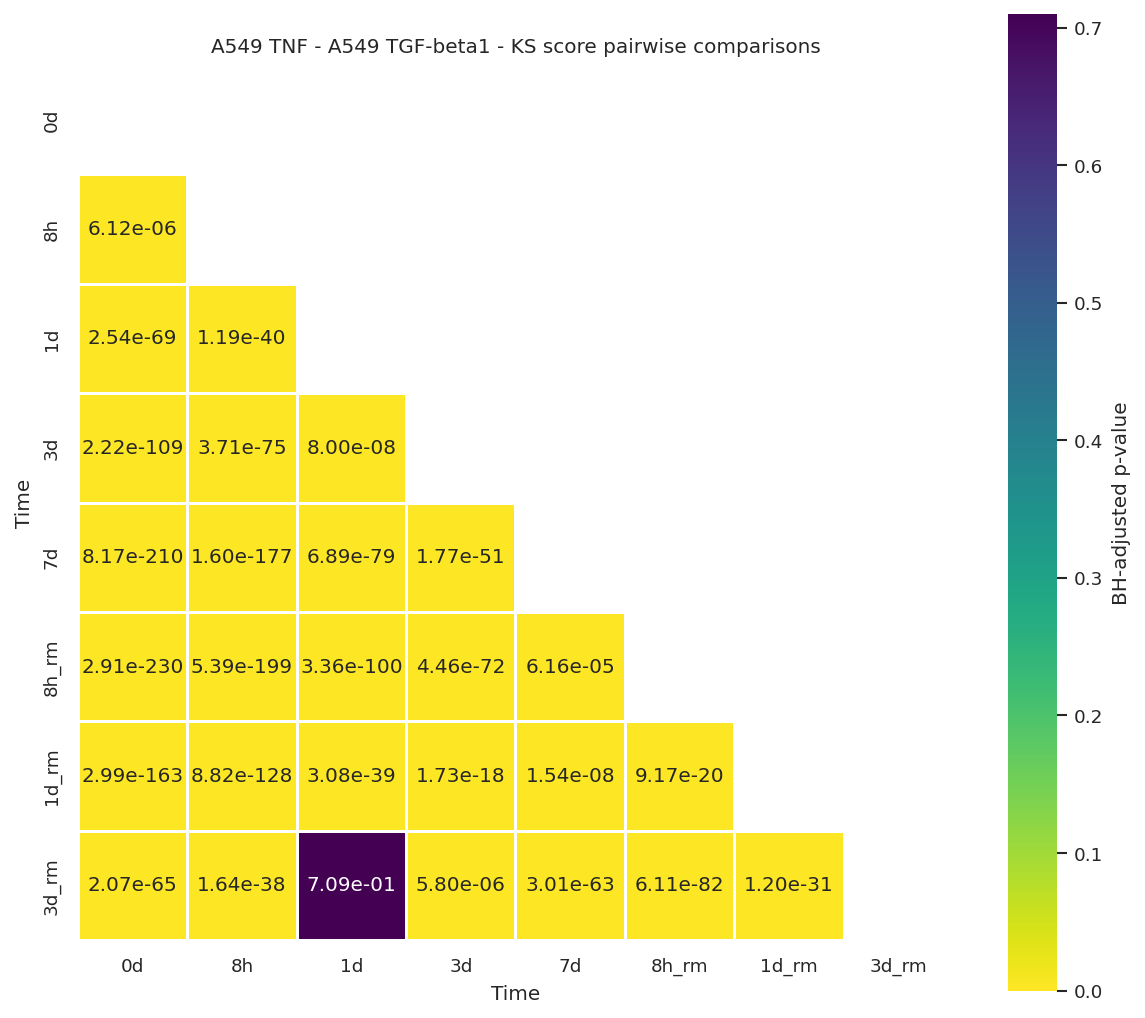

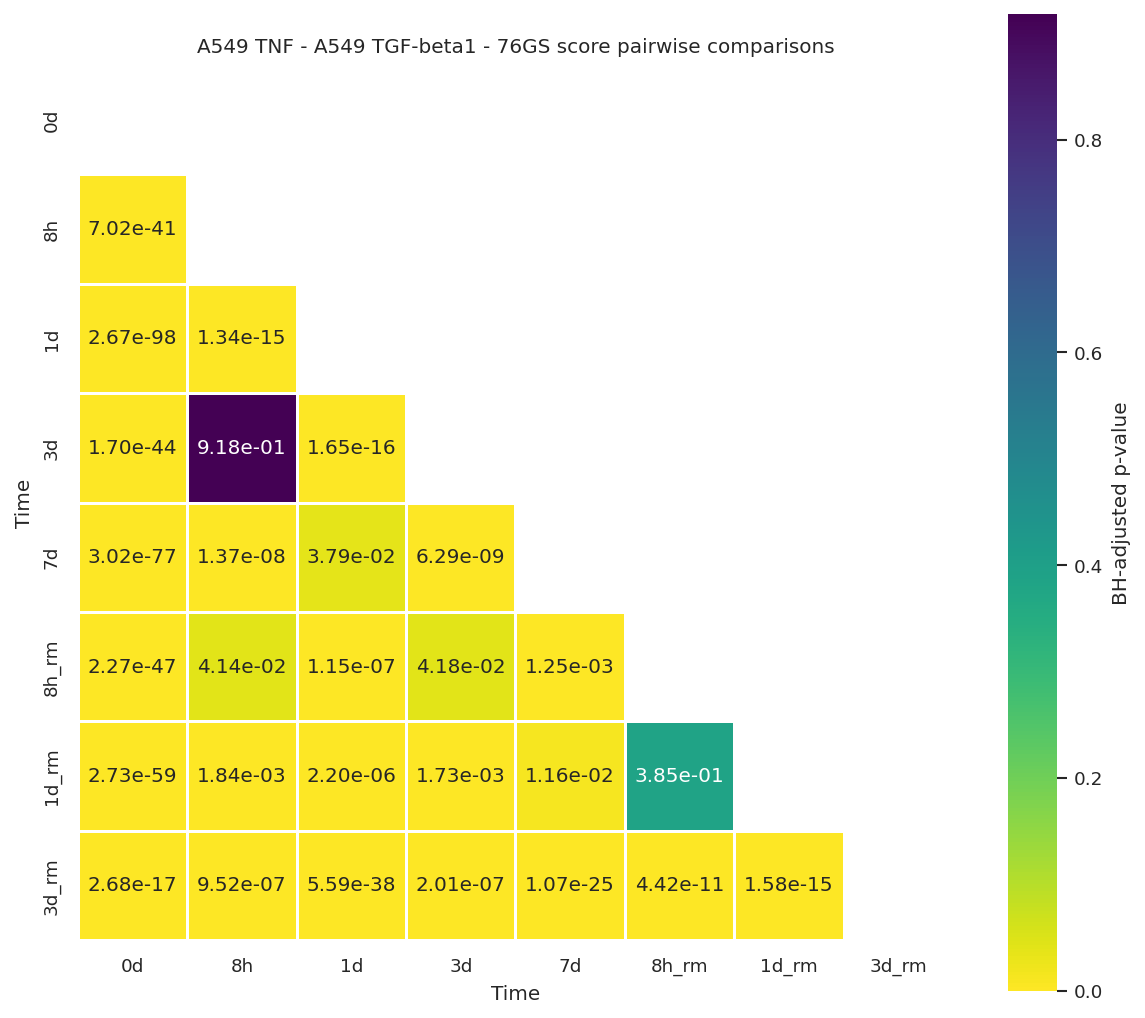

In [6]:
def pairwise_fdr(score):
    rows = []
    for first, second in combinations(TIME_ORDER, 2):
        x = cells.loc[cells['Time'] == first, score].dropna()
        y = cells.loc[cells['Time'] == second, score].dropna()
        statistic, pvalue = ttest_ind(x, y, equal_var=False)
        rows.append({'Time1': first, 'Time2': second, 't_stat': statistic, 'p': pvalue, 'n1': len(x), 'n2': len(y)})
    result = pd.DataFrame(rows)
    result['p_adj'] = multipletests(result['p'], method='fdr_bh')[1]
    matrix = pd.DataFrame(np.nan, index=TIME_ORDER, columns=TIME_ORDER)
    for _, row in result.iterrows():
        matrix.loc[row['Time1'], row['Time2']] = row['p_adj']; matrix.loc[row['Time2'], row['Time1']] = row['p_adj']
    return result, matrix

for score, label, name in [('KS_score', 'KS', 'panel07_ks_pairwise'), ('GS76_score', '76GS', 'panel08_gs76_pairwise')]:
    result, matrix = pairwise_fdr(score)
    result.to_csv(SOURCE / f'{name}.csv', index=False); matrix.to_csv(SOURCE / f'{name}_matrix.csv')
    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(matrix, mask=np.triu(np.ones_like(matrix, dtype=bool)), annot=True, fmt='.2e', cmap='viridis_r', linewidths=0.5, square=True, cbar_kws={'label': 'BH-adjusted p-value'}, ax=ax)
    title(ax, f'A549 TGF-beta1 - {label} score pairwise comparisons')
    ax.set_xlabel('Time'); ax.set_ylabel('Time')
    fig.tight_layout(); save_figure(fig, name); plt.show()

## Network score and intrinsic dimension

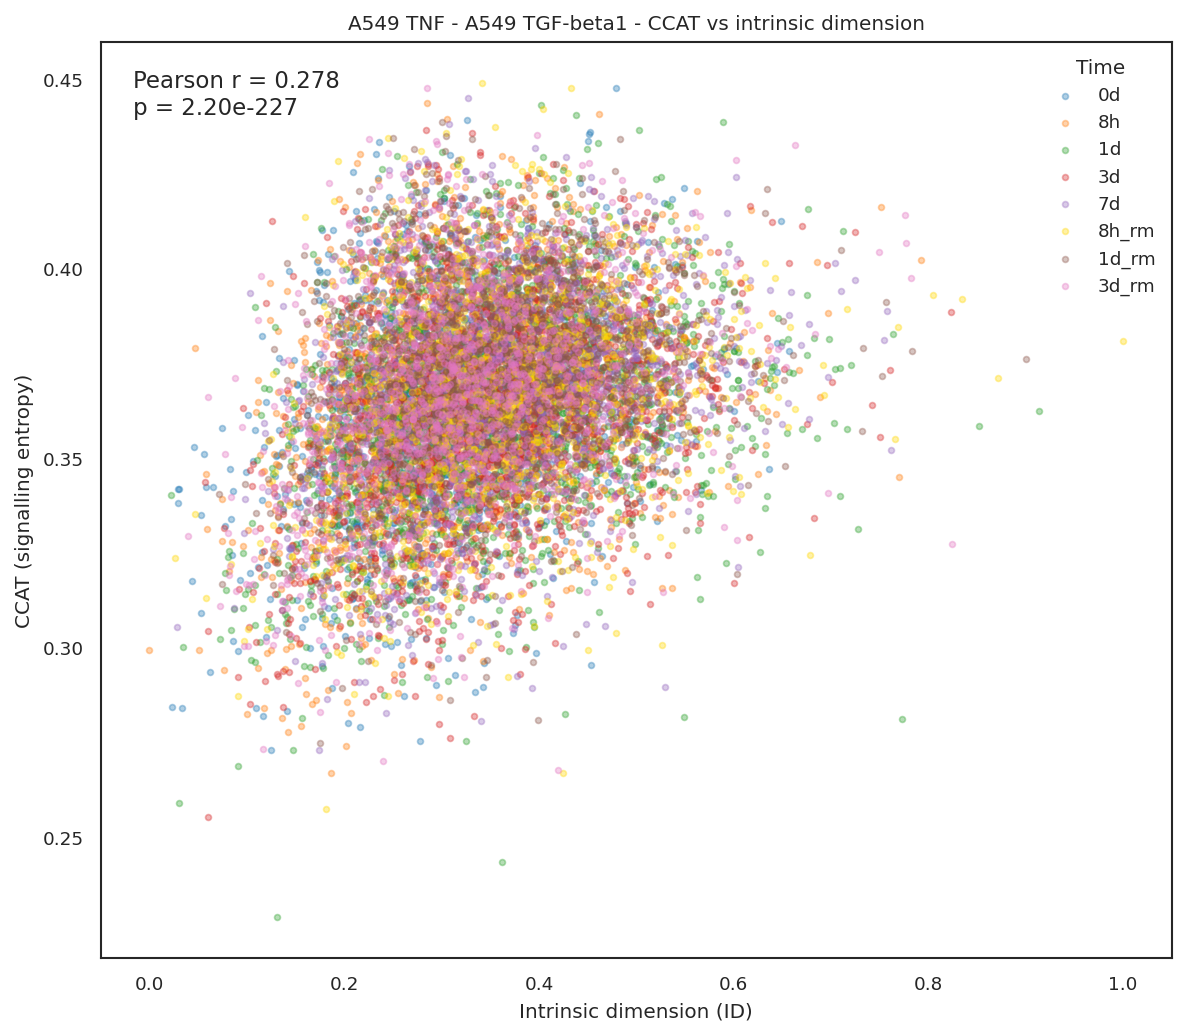

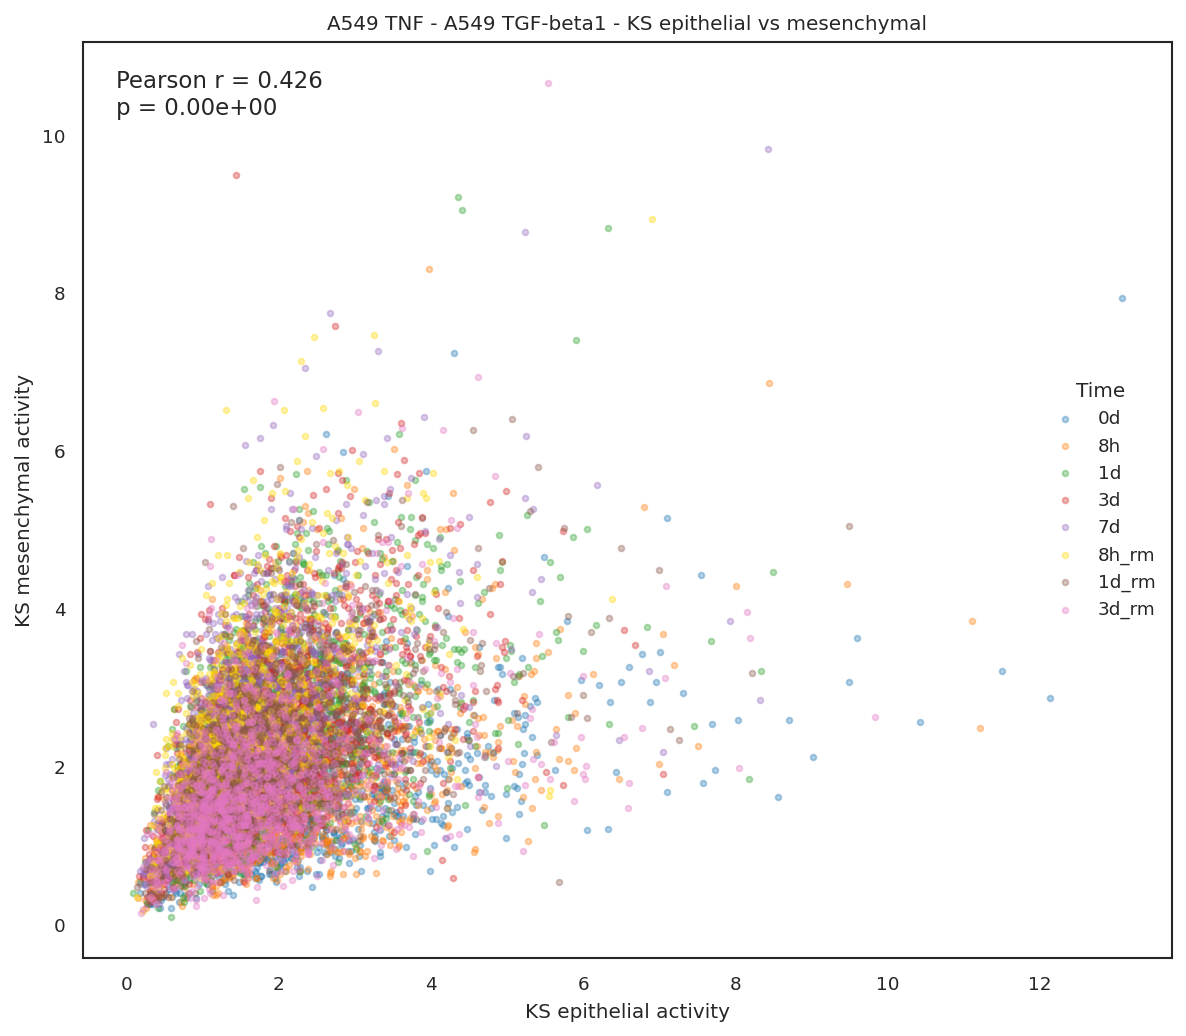

In [7]:
def scatter_panel(x, y, xlabel, ylabel, title_text, name, correlation_name):
    data = cells[[x, y, 'Time']].dropna()
    pearson = pearsonr(data[x], data[y]); spearman = spearmanr(data[x], data[y])
    pd.DataFrame([{'method': 'pearson', 'r': pearson.statistic, 'p': pearson.pvalue}, {'method': 'spearman', 'r': spearman.statistic, 'p': spearman.pvalue}]).to_csv(SOURCE / correlation_name, index=False)
    fig, ax = plt.subplots(figsize=(8, 7))
    for time in TIME_ORDER:
        subset = data[data['Time'] == time]
        ax.scatter(subset[x], subset[y], s=8, alpha=0.35, color=TIME_COLORS[time], label=time)
    ax.text(0.03, 0.97, f'Pearson r = {pearson.statistic:.3f}\np = {pearson.pvalue:.2e}', transform=ax.transAxes, ha='left', va='top', fontsize=11)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); title(ax, title_text)
    ax.legend(title='Time', frameon=False); fig.tight_layout(); save_figure(fig, name); plt.show()

scatter_panel('ID', 'CCAT', 'Intrinsic dimension (ID)', 'CCAT (signalling entropy)', 'A549 TGF-beta1 - CCAT vs intrinsic dimension', 'panel09_id_vs_ccat', 'panel09_id_vs_ccat_correlation.csv')
scatter_panel('KS_epi', 'KS_mes', 'KS epithelial activity', 'KS mesenchymal activity', 'A549 TGF-beta1 - KS epithelial vs mesenchymal', 'panel10_ks_epi_vs_mes', 'panel10_ks_epi_vs_mes_correlation.csv')

## Source data

`Input_A549_percell.csv` contains one row per cell and all values used to make the figures: experimental time, phenotype, CCAT, KS, 76GS, intrinsic dimension, and the epithelial/mesenchymal KS component scores. The remaining CSVs are generated summaries, correlations, and multiple-comparison results.